# 04 — Élasticité-prix : six estimateurs, une seule bonne réponse

L'élasticité-prix `e` répond à : *si j'augmente mon prix de 1 %, mon volume
varie de combien de pour cent ?* C'est le paramètre qui transforme un modèle en
décision tarifaire.

**Le problème central est l'endogénéité du prix.** Un vendeur augmente son prix
quand il anticipe une demande forte et solde quand elle faiblit. La corrélation
brute mélange donc deux mécanismes de sens opposé :

```
prix ──(effet demande, négatif)──► quantité
prix ◄──(effet anticipation, positif)── demande latente
```

Résultat : l'élasticité naïve est **biaisée vers zéro**, voire positive.

Ce notebook applique six estimateurs à la même donnée, du plus naïf au plus
crédible, pour rendre ce biais visible plutôt que de le cacher.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

# Le package est importable depuis le dossier notebooks/
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.25})

In [2]:
from optimization_pricing.dataset import load_panel

panel = load_panel("product", processed=True)
panel_cat = load_panel("category", processed=True)
print(f"{len(panel):,} observations produit-mois | {panel['product_id'].nunique():,} produits")

28,636 observations produit-mois | 5,933 produits


## Étape 0 — Valider la méthode sur données simulées

Avant de faire confiance à un estimateur sur des données réelles où l'on ne
connaît pas la réponse, on le teste sur des données simulées où **on la
connaît**. Ici : élasticité vraie de −1.5, avec une saisonnalité qui pousse
simultanément le prix et la demande (le confondant classique).

In [3]:
rng = np.random.default_rng(0)
n_produits, n_mois, elasticite_vraie = 300, 12, -1.5

lignes = []
for pid in range(n_produits):
    prix_base = np.exp(rng.normal(4.0, 0.6))
    demande_base = np.exp(rng.normal(1.5, 0.5))
    for m in range(n_mois):
        saison = np.sin(m / 12 * 2 * np.pi)
        prix = prix_base * np.exp(0.20 * saison + rng.normal(0, 0.15))
        demande = (
            demande_base
            * (prix / prix_base) ** elasticite_vraie
            * np.exp(0.5 * saison + rng.normal(0, 0.20))
        )
        lignes.append({"product_id": pid, "month": m, "price": prix, "quantity": max(demande, 0.5)})

simule = pd.DataFrame(lignes)
simule["log_price"] = np.log(simule["price"])
simule["log_quantity"] = np.log(simule["quantity"])

from optimization_pricing.elasticity import _fe_regression, pooled_ols

naif = pooled_ols(simule)["elasticity"]
fe = _fe_regression(simule, "log_quantity", "log_price", ["product_id", "month"])["elasticity"]

print(f"Elasticite VRAIE                     : {elasticite_vraie:+.3f}")
print(f"OLS poolee (naive)                   : {naif:+.3f}   <- biaisee vers zero")
print(f"Effets fixes produit + mois          : {fe:+.3f}   <- retrouve la verite")

Elasticite VRAIE                     : -1.500
OLS poolee (naive)                   : -0.124   <- biaisee vers zero
Effets fixes produit + mois          : -1.551   <- retrouve la verite


La méthode fonctionne : les effets fixes retrouvent l'élasticité vraie là où
l'OLS naïve se trompe d'un facteur important. On peut maintenant l'appliquer aux
données réelles avec un minimum de confiance.

## Estimateur 1 — OLS poolée : ce qu'on lirait sans réfléchir

Aucun contrôle. On compare des produits différents entre eux.

In [4]:
res_pooled = pooled_ols(panel)
print(f"Elasticite : {res_pooled['elasticity']:+.3f} (ecart-type {res_pooled['std_error']:.3f})")
print(f"R2         : {res_pooled['r2']:.4f}")

Elasticite : -0.020 (ecart-type 0.004)
R2         : 0.0006


Une élasticité de −0.02 signifierait qu'on peut doubler ses prix sans presque
rien perdre. C'est évidemment faux : ce coefficient mélange l'effet prix et
l'effet produit (un livre à 20 BRL ne se vend pas plus qu'une montre à 400 BRL
*parce qu'il* est moins cher).

## Estimateur 2 — Effets fixes catégorie × semaine

L'approche « standard » sur données de marketplace : on absorbe les différences
entre catégories et la saisonnalité mensuelle.

In [5]:
from optimization_pricing.elasticity import category_fixed_effects

res_cat = category_fixed_effects(panel_cat)
print(f"Elasticite : {res_cat['elasticity']:+.3f} (ecart-type {res_cat['std_error']:.3f})")
print(f"p-value    : {res_cat['p_value']:.3f}")
print(f"Effets fixes absorbes : {res_cat['n_absorbed']}")

Elasticite : -0.024 (ecart-type 0.036)
p-value    : 0.503
Effets fixes absorbes : 43


**L'élasticité s'effondre au lieu de se creuser.** Ce n'est pas que la demande
soit insensible au prix : c'est que le prix moyen d'une catégorie une semaine
donnée reflète surtout le **mix produits** vendu (cf. notebook 02).
L'agrégation a détruit le signal avant qu'on essaie de l'estimer.

## Estimateur 3 — Effets fixes produit × mois **(référence)**

On change d'unité de comparaison : plus des produits entre eux, mais **un
produit avec lui-même** d'un mois sur l'autre.

* effet fixe **produit** → absorbe qualité, marque, gamme, catégorie ;
* effet fixe **mois** → absorbe saison, macro, Black Friday ;
* il reste la variation de prix décidée par le vendeur.

Deux contrôles sont volontairement **absents** :
* `log_quantity_lag1` : une variable dépendante retardée dans un modèle à
  effets fixes est inconsistante (**biais de Nickell**) ;
* `n_sellers` : calculé sur les mêmes transactions que la quantité, c'est un
  contrôle post-traitement qui absorberait une partie de l'effet.

In [6]:
from optimization_pricing.elasticity import product_fixed_effects

res_prod = product_fixed_effects(panel)
for cle in ("elasticity", "std_error", "t_stat", "p_value", "n_obs", "n_absorbed", "r2_within"):
    print(f"{cle:12s} : {res_prod[cle]:,.4f}")

elasticity   : -0.7483
std_error    : 0.0503
t_stat       : -14.8714
p_value      : 0.0000
n_obs        : 28,636.0000
n_absorbed   : 5,952.0000
r2_within    : 0.0150


**≈ −0.74, très significatif.** Lecture métier : +1 % de prix → environ −0.74 %
de volume. La demande est **inélastique** (|e| < 1) : sur cette plage, une
hausse de prix augmente le chiffre d'affaires.

### Robustesse au choix des contrôles

In [7]:
jeux_de_controles = [
    [],
    ["log_freight"],
    ["log_freight", "product_age_months"],
    ["log_freight", "product_age_months", "log_cum_sales"],
    ["log_quantity_lag1"],
]

robustesse = pd.DataFrame(
    [
        {
            "controles": ", ".join(c) or "aucun",
            **{
                k: v
                for k, v in _fe_regression(
                    panel, "log_quantity", "log_price", ["product_id", "month"], c
                ).items()
                if k in ("elasticity", "std_error")
            },
        }
        for c in jeux_de_controles
    ]
)
robustesse

,controles,elasticity,std_error
0,aucun,-0.746,0.050
1,log_freight,-0.748,0.050
2,"log_freight, product_age_months",-0.748,0.050
3,"log_freight, product_age_months, log_cum_sales",-0.748,0.050
4,log_quantity_lag1,-0.712,0.050


L'estimation reste dans une fourchette étroite quel que soit le jeu de
contrôles : le résultat ne dépend pas d'un choix de spécification particulier.
La dernière ligne (avec la variable dépendante retardée) est celle qui bouge le
plus — c'est le biais de Nickell, et c'est pourquoi elle est écartée.

## Estimateur 4 — Double Machine Learning, et le piège à éviter

Le DoubleML orthogonalise : deux modèles ML apprennent `E[log Q | X]` et
`E[log P | X]`, puis on régresse résidus sur résidus.

On le lance **deux fois**, pour montrer un piège fréquent.

In [8]:
from optimization_pricing.elasticity import double_ml_elasticity, within_price_variance_share

part_intra = within_price_variance_share(panel)
print(f"Part de la variance de log-prix qui est intra-produit : {part_intra:.2%}\n")

res_dml_naif = double_ml_elasticity(panel, absorb_fixed_effects=False)
print(f"DoubleML SANS absorption des effets fixes : {res_dml_naif['elasticity']:+.3f}")

res_dml = double_ml_elasticity(panel, absorb_fixed_effects=True)
print(f"DoubleML APRES absorption (FWL)           : {res_dml['elasticity']:+.3f}")
print(f"  intervalle de confiance 95 % : [{res_dml['confidence_interval'][0]:.3f}, {res_dml['confidence_interval'][1]:.3f}]")

Part de la variance de log-prix qui est intra-produit : 0.82%



C:\Users\DELL\Desktop\Projet Data\Data Science\.env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DoubleML SANS absorption des effets fixes : -0.120


DoubleML APRES absorption (FWL)           : -0.738
  intervalle de confiance 95 % : [-0.825, -0.651]


**Le machine learning ne remplace pas l'identification.**

Sans absorption préalable, le DoubleML renvoie une élasticité proche de zéro,
comme l'OLS naïve. La raison est arithmétique : seul ~1 % de la variance du
log-prix est intra-produit. La régularisation du modèle ML laisse passer une
partie de l'identité produit, les résidus de prix restent dominés par la
variation **entre** produits (dont l'élasticité apparente est nulle), et le
coefficient est tiré vers zéro.

Une fois les effets fixes retirés au préalable (théorème de Frisch-Waugh-Lovell),
le DoubleML **confirme** l'estimation par effets fixes — ce qui est rassurant :
la relation ne dépend pas d'une hypothèse de linéarité sur les contrôles.

## Estimateur 5 — Poisson PPML : la demande est un comptage

La médiane de la demande produit-mois vaut 1, et `log(1) = 0`. Le modèle
log-log écrase donc une grande partie de l'information. Le PPML modélise
directement le comptage.

Contrainte technique : le PPML n'admet pas le centrage linéaire des effets
fixes, il faut de vraies dummies → estimation restreinte aux 600 meilleures
ventes. **C'est un échantillon sélectionné**, à lire comme tel.

In [9]:
from optimization_pricing.elasticity import poisson_ppml

res_ppml = poisson_ppml(panel, top_products=600)
print(f"Elasticite : {res_ppml['elasticity']:+.3f} (ecart-type {res_ppml['std_error']:.3f})")
print(f"Estimee sur {res_ppml['n_products']} produits, {res_ppml['n_obs']:,} observations")

Elasticite : -1.811 (ecart-type 0.188)
Estimee sur 600 produits, 5,622 observations


Nettement plus élastique. Ce n'est pas une contradiction, c'est une
**information** : les produits à fort volume sont plus sensibles au prix que la
moyenne du catalogue — ils sont plus comparés, plus substituables. À traiter
comme une borne (la plus négative), pas comme l'estimation centrale.

## Synthèse : le même jeu de données, six réponses

In [10]:
estimateurs = {
    "OLS poolee": res_pooled,
    "FE categorie x semaine": res_cat,
    "FE produit x mois": res_prod,
    "DoubleML sans FE": res_dml_naif,
    "DoubleML avec FE": res_dml,
    "Poisson PPML (top 600)": res_ppml,
}

synthese = pd.DataFrame(
    [
        {
            "estimateur": nom,
            "elasticite": r.get("elasticity", np.nan),
            "ecart-type": r.get("std_error", np.nan),
            "identification": (
                "aucune" if "poolee" in nom or "sans FE" in nom
                else "agregee (mix)" if "categorie" in nom
                else "intra-produit"
            ),
        }
        for nom, r in estimateurs.items()
    ]
)
synthese

,estimateur,elasticite,ecart-type,identification
0,OLS poolee,-0.020,0.004,aucune
1,FE categorie x semaine,-0.024,0.036,agregee (mix)
2,FE produit x mois,-0.748,0.050,intra-produit
3,DoubleML sans FE,-0.120,0.010,aucune
4,DoubleML avec FE,-0.738,0.045,intra-produit
5,Poisson PPML (top 600),-1.811,0.188,intra-produit


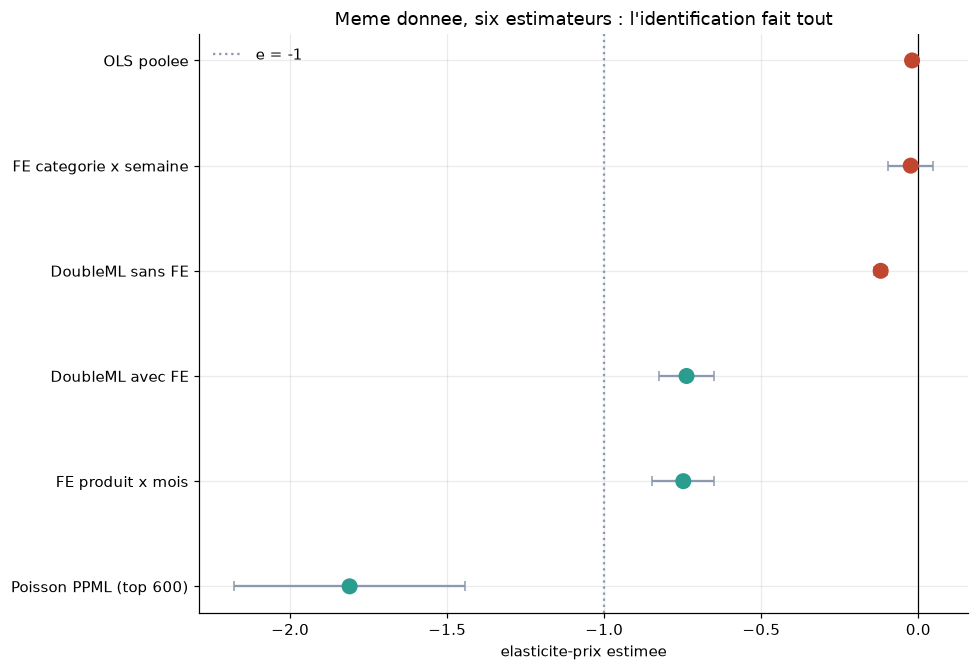

In [11]:
from optimization_pricing import plots

plots.plot_estimator_comparison(
    {nom: r for nom, r in estimateurs.items()}, save=True
)
plt.show()

## Élasticités par catégorie et rétrécissement bayésien

Une élasticité unique ne suffit pas pour piloter : les catégories n'ont pas la
même sensibilité au prix. Mais estimer catégorie par catégorie fait exploser le
bruit — on obtient parfois des élasticités **positives**, économiquement
absurdes, qui feraient recommander des hausses de prix illimitées.

**Solution : le rétrécissement empirique de Bayes** (James-Stein). Chaque
estimation est tirée vers la moyenne globale proportionnellement à son
imprécision :

$$ w_c = \frac{\tau^2}{\tau^2 + \sigma_c^2} \qquad
   \hat{e}_c^{\text{final}} = w_c \hat{e}_c + (1 - w_c)\, \bar{e} $$

Une catégorie bien mesurée garde son élasticité propre ; une catégorie bruitée
hérite quasiment de l'élasticité globale.

In [12]:
from optimization_pricing.elasticity import elasticity_by_category

par_categorie = elasticity_by_category(panel, global_elasticity=res_prod["elasticity"])
par_categorie[
    ["category", "elasticity", "std_error", "shrinkage_weight", "elasticity_pricing", "n_obs"]
].head(15)

2026-08-20 10:40:22.877 | INFO     | optimization_pricing.elasticity:elasticity_by_category:414 - Elasticites par categorie : 28 categories | moyenne brute -0.60 -> retrecie -0.66 (tau=0.42)


,category,elasticity,std_error,shrinkage_weight,elasticity_pricing,n_obs
0,watches_gifts,-1.387,0.191,0.828,-1.277,1549
1,bed_bath_table,-1.336,0.192,0.826,-1.234,3280
2,luggage_accessories,-1.557,0.505,0.409,-1.079,261
3,office_furniture,-1.297,0.392,0.534,-1.041,560
4,toys,-1.064,0.249,0.739,-0.982,1035
5,cool_stuff,-1.088,0.324,0.627,-0.961,1093
6,garden_tools,-0.979,0.343,0.600,-0.886,573
7,health_beauty,-0.888,0.168,0.862,-0.869,2196
8,perfumery,-0.939,0.323,0.628,-0.868,803
9,books_general_interest,-1.203,0.719,0.254,-0.864,159


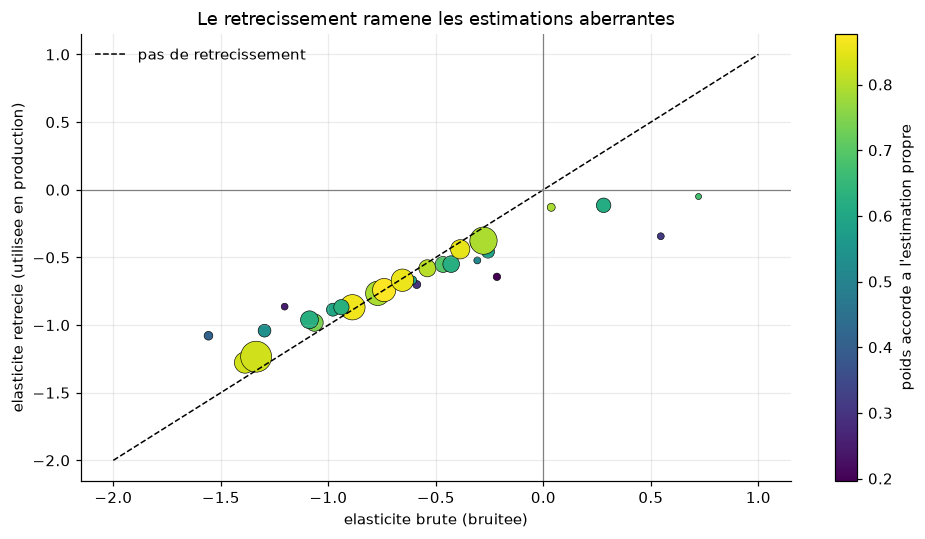

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(
    par_categorie["elasticity"],
    par_categorie["elasticity_pricing"],
    s=par_categorie["n_obs"] / 8,
    c=par_categorie["shrinkage_weight"],
    cmap="viridis",
    edgecolors="black",
    linewidths=0.4,
)
lims = [-2.0, 1.0]
ax.plot(lims, lims, "k--", lw=1, label="pas de retrecissement")
ax.axhline(0, color="grey", lw=0.8)
ax.axvline(0, color="grey", lw=0.8)
ax.set_xlabel("elasticite brute (bruitee)")
ax.set_ylabel("elasticite retrecie (utilisee en production)")
ax.set_title("Le retrecissement ramene les estimations aberrantes")
plt.colorbar(ax.collections[0], ax=ax, label="poids accorde a l'estimation propre")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

Les points loin de la diagonale sont les catégories mal mesurées : leur
estimation brute est corrigée. Les catégories à droite de zéro (élasticité brute
positive) sont ramenées dans le domaine économiquement plausible.

## Du coefficient au prix : la règle de Lerner

La condition d'optimalité du monopole relie directement l'élasticité au taux de
marge :

$$ \frac{p^* - c}{p^*} = -\frac{1}{e} \qquad \Longleftrightarrow \qquad
   p^* = \frac{c}{1 + 1/e} $$

**Lecture métier : le taux de marge optimal est l'inverse de l'élasticité.**

In [14]:
from optimization_pricing.elasticity import margin_rate_from_elasticity

grille = pd.DataFrame({"elasticite": [-1.25, -1.5, -2.0, -2.5, -3.0, -4.0, -5.0]})
grille["taux de marge optimal"] = margin_rate_from_elasticity(grille["elasticite"].to_numpy())
grille["prix optimal si cout = 60"] = 60 / (1 + 1 / grille["elasticite"])
grille

,elasticite,taux de marge optimal,prix optimal si cout = 60
0,-1.250,0.800,300.000
1,-1.500,0.667,180.000
2,-2.000,0.500,120.000
3,-2.500,0.400,100.000
4,-3.000,0.333,90.000
5,-4.000,0.250,80.000
6,-5.000,0.200,75.000


### Le diagnostic le plus utile du projet

En inversant la formule : à un taux de marge donné, le prix courant est déjà
optimal si et seulement si `e = -1 / marge`. C'est l'**élasticité de
rentabilité**.

Hypothese de cout : 60% du prix -> marge brute 40%
Elasticite de rentabilite : -2.50

Categories moins elastiques que le seuil (sous-tarifees) : 28 / 28


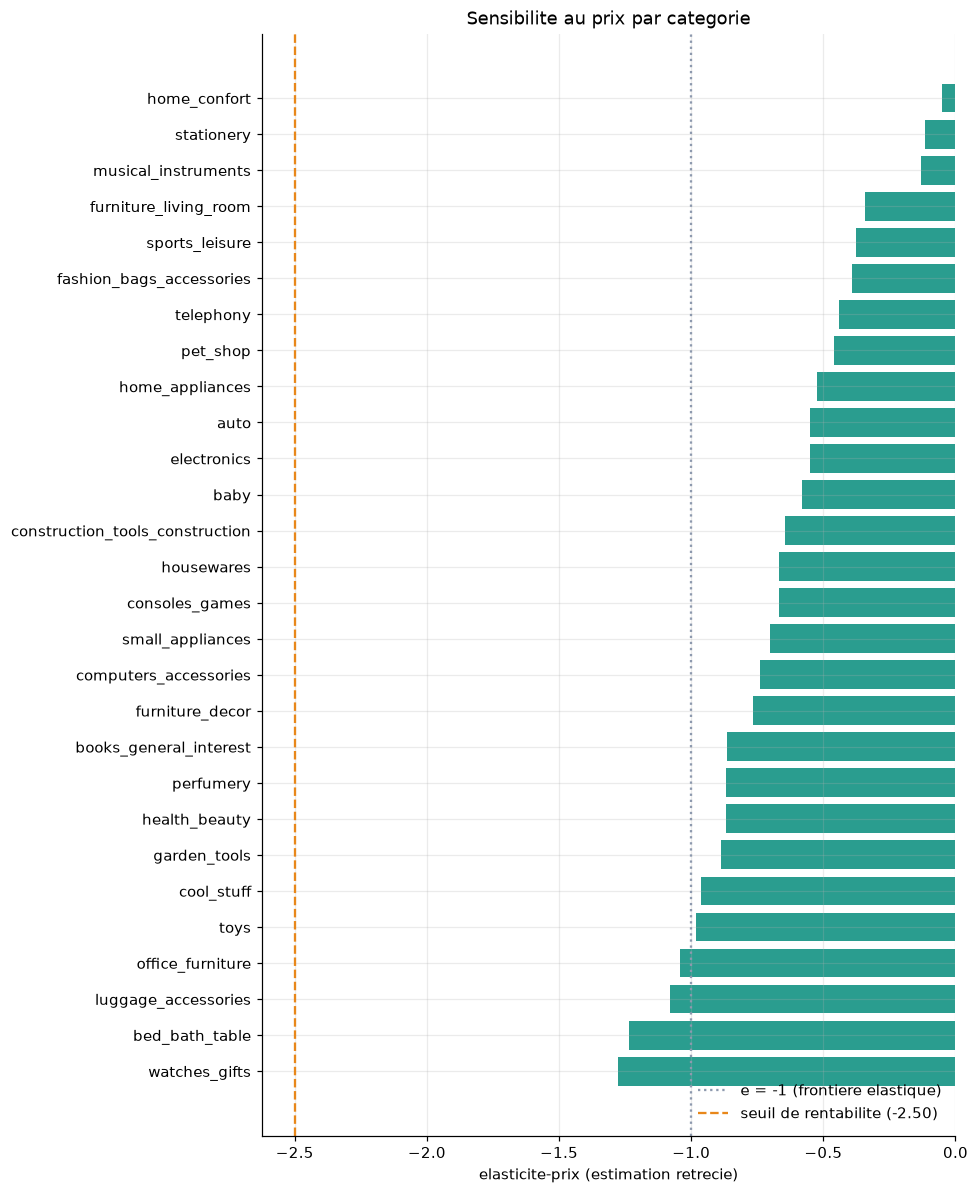

In [15]:
from optimization_pricing.config import DEFAULT_COST_RATIO
from optimization_pricing.optimizer import breakeven_elasticity

seuil = breakeven_elasticity(1 - DEFAULT_COST_RATIO)
print(f"Hypothese de cout : {DEFAULT_COST_RATIO:.0%} du prix -> marge brute {1 - DEFAULT_COST_RATIO:.0%}")
print(f"Elasticite de rentabilite : {seuil:.2f}\n")

sous_tarifees = par_categorie.loc[par_categorie["elasticity_pricing"] > seuil]
print(f"Categories moins elastiques que le seuil (sous-tarifees) : {len(sous_tarifees)} / {len(par_categorie)}")

plots.plot_elasticity_by_category(
    par_categorie.rename(columns={"elasticity_pricing": "elasticity_final"}).assign(
        elasticity=lambda d: d["elasticity_final"]
    ),
    breakeven=seuil,
    save=True,
)
plt.show()

**Toutes les catégories sont au-dessus du seuil.** Sous l'hypothèse d'une marge
brute de 40 %, le modèle conclut que les prix Olist sont, en moyenne, en dessous
du niveau qui maximise le profit.

C'est un résultat fort — et à manier avec précaution :
* il dépend entièrement de l'hypothèse de coût (testée au notebook 06) ;
* l'élasticité mesurée est de **court terme** : elle ignore la réaction des
  concurrents et l'effet sur le référencement ;
* elle est estimée sur des mouvements de prix modérés — l'extrapoler à +25 %
  est déjà une extension du domaine de validité.

In [16]:
from optimization_pricing.elasticity import estimate_all

# run_dml=True : l'artefact de production doit contenir TOUS les estimateurs,
# y compris les deux variantes DoubleML (le rapport et l'API les affichent).
artefact = estimate_all(panel, panel_cat, run_dml=True, save=True)
print(f"Artefact sauvegarde. Elasticite de reference : {artefact['reference_elasticity']:.3f}")

2026-08-20 10:40:24.018 | INFO     | optimization_pricing.elasticity:estimate_all:464 - OLS poolee            : -0.020


2026-08-20 10:40:24.057 | INFO     | optimization_pricing.elasticity:estimate_all:470 - Effets fixes categorie: -0.024


2026-08-20 10:40:24.854 | INFO     | optimization_pricing.elasticity:estimate_all:476 - Effets fixes produit  : -0.748


2026-08-20 10:41:39.695 | INFO     | optimization_pricing.elasticity:estimate_all:480 - Poisson PPML          : -1.811


2026-08-20 10:41:58.696 | INFO     | optimization_pricing.elasticity:estimate_all:490 - DoubleML sans FE      : -0.113  (piege)


2026-08-20 10:42:02.208 | INFO     | optimization_pricing.elasticity:estimate_all:493 - DoubleML avec FE      : -0.745


2026-08-20 10:42:02.482 | INFO     | optimization_pricing.elasticity:estimate_all:501 - Variance de prix intra-produit : 0.8% du total


2026-08-20 10:42:05.499 | INFO     | optimization_pricing.elasticity:elasticity_by_category:414 - Elasticites par categorie : 28 categories | moyenne brute -0.60 -> retrecie -0.66 (tau=0.42)


2026-08-20 10:42:05.507 | SUCCESS  | optimization_pricing.elasticity:estimate_all:526 - Elasticites sauvegardees : C:\Users\DELL\Desktop\Projet Data\Data Science\Dynamic Pricing\optimization_pricing\models\elasticities.json


Artefact sauvegarde. Elasticite de reference : -0.748


## Ce que ce notebook établit

| Estimateur | Élasticité | Verdict |
|---|---|---|
| OLS poolée | ≈ −0.02 | compare des produits différents : sans valeur |
| FE catégorie × semaine | ≈ −0.02 | l'agrégation a détruit le signal |
| **FE produit × mois** | **≈ −0.74** | **référence retenue** |
| DoubleML sans FE | ≈ −0.12 | le ML ne remplace pas l'identification |
| DoubleML avec FE | ≈ −0.72 | confirme la référence |
| Poisson PPML (top 600) | ≈ −1.81 | les best-sellers sont plus élastiques |

Les élasticités par catégorie sont rétrécies pour rester utilisables en
production, puis sauvegardées dans `models/elasticities.json`.

**Suite :** notebook 05, le modèle de demande qui capte ce que la régression
linéaire ne peut pas voir.